# MAKE_VIDEO · story text → cartoon video

**To make a new video**
1. Copy a file in `stories/` (for example `1_golden_mango.txt`), give it a new name, and write your own story in it  
   (format: see `SYNTAX.md` - it is just names, feelings and lines of dialogue).
2. Change `STORY` in the first cell below to your file.
3. Menu **Run → Run All Cells**. The video appears in `output/`.

Voices are made with free Microsoft neural voices (**internet needed once per new line**). Lines you did not change are reused, so editing a story is fast.

In [1]:
STORY = "stories/3_straw_on_the_thief.txt"     # <- change to your story file, e.g. "stories/3_straw_on_the_thief.txt"

USE_DRAFT_VOICE_IF_OFFLINE = False        # True = if real voices fail, use a humming PLACEHOLDER (testing only!)

## 1 · Check this computer

In [2]:
# First time only (or if something is missing): remove the # on the next line and run this cell, then restart the kernel.
# %pip install -U edge-tts uharfbuzz pillow numpy fonttools

from engine import check_setup
check_setup()

  OK   ffmpeg installed
  OK   Pillow 12.3.0
  OK   Bangla text shaping (uharfbuzz - built-in fix)
  OK   numpy
  OK   fontTools
  OK   edge_tts
  OK   fonts/NotoSansBengali-Bold.ttf

Ready to go.


True

## 2 · Read the story

In [3]:
from engine.script import load_story, describe, ScriptError

try:
    story = load_story(STORY)
except ScriptError as e:
    print("PROBLEM IN YOUR STORY FILE\n")
    print(e)
    raise SystemExit("Fix the story file and run this cell again.")
describe(story)

Title: চোরের মাথায় খড়
Characters: raja (রাজা কৃষ্ণচন্দ্র), bonik (বণিক), chor (বাঁশিওয়ালা), chikna (চিকনা ভাঁড়)
Scenes: 2   Spoken lines: 16   Estimated length: about 102 seconds


## 3 · Voices
Makes one voice file per line in `audio/`. Each character gets its own voice, speed, pitch and a *voice effect* (`fx`) that makes the voice deeper or higher, so characters sound different.  
Lines that already have a voice are skipped. Want to use your **own recording** instead? Save it as `audio/line_03.mp3` (the line number) - it is used automatically.

In [4]:
from engine import audio
import traceback

print("Making voices (lines that already have one are skipped)...")

tts_error = None
try:
    await audio.tts_all(story, "audio")
except Exception as e:
    tts_error = e
    print("\nTTS ERROR:")
    traceback.print_exc()
    if USE_DRAFT_VOICE_IF_OFFLINE:
        print("\nMaking placeholder hum voices (NOT real speech) so you can test the animation.")
        audio.make_all_draft_audio(story, "audio")

status = audio.audio_status(story, "audio")

print("\n========== AUDIO STATUS ==========")
for lid, who, state, text in status:
    mark = {"real": "OK", "draft": "DRAFT", "missing": "MISSING"}.get(state, "UNKNOWN")
    print(f"{mark:8} | {lid:16} | {who:10} | {text[:60]}")

missing = [s for s in status if s[2] == "missing"]
draft = [s for s in status if s[2] == "draft"]
real = [s for s in status if s[2] == "real"]

print("\n========== SUMMARY ==========")
print("Real voices:   ", len(real))
print("Draft voices:  ", len(draft), "(humming placeholder - not real speech)" if draft else "")
print("Missing voices:", len(missing))

if missing:
    print("\nMissing dialogue:")
    for item in missing:
        print(" ", item[0], "-", item[1], "-", item[3][:80])
    raise SystemExit("Stopped: some lines have no voice yet. Fix the error above (internet? edge-tts installed?) and run this cell again.")
print("\nAll dialogue lines have audio!")

Making voices (lines that already have one are skipped)...
  made   line_01_4d447b  bonik    bn-BD-PradeepNeural  fx -4
  made   line_02_2f2609  chikna   bn-BD-PradeepNeural  fx +3
  made   line_03_8631c7  bonik    bn-BD-PradeepNeural  fx -4
  made   line_04_df8dc0  chor     bn-IN-BashkarNeural  fx +2
  made   line_05_4ecf3d  chikna   bn-BD-PradeepNeural  fx +3
  made   line_06_ed8d1a  chikna   bn-BD-PradeepNeural  fx +3
  made   line_07_9cef0b  chikna   bn-BD-PradeepNeural  fx +3
  made   line_08_259d38  chor     bn-IN-BashkarNeural  fx +2
  made   line_09_6f0cbb  raja     bn-IN-BashkarNeural  fx -2
  made   line_10_e6df66  chor     bn-IN-BashkarNeural  fx +2
  made   line_11_854944  raja     bn-IN-BashkarNeural  fx -2
  made   line_12_fd6966  chikna   bn-BD-PradeepNeural  fx +3
  made   line_13_92cc65  chikna   bn-BD-PradeepNeural  fx +3
  made   line_14_25c0fd  bonik    bn-BD-PradeepNeural  fx -4
  made   line_15_7f254b  raja     bn-IN-BashkarNeural  fx -2
  made   line_16_812a32  c

Listen to the first lines:

In [5]:
from IPython.display import Audio, display
for lid, who, state, text in status[:3]:
    p = audio.find_audio("audio", lid)
    if p:
        print(who, "-", text[:50])
        display(Audio(str(p)))

bonik - হায় হায়! আমার সোনার মোহরের থলিটা কে নিল? এই তো এ


chikna - কী হয়েছে ভাই? এমন চেঁচাচ্ছ কেন?


bonik - চিকনাবাবু, আমার থলি চুরি গেছে। এখানে তো আমি আর এই 


## 4 · Preview some frames (quick, no video yet)

In [6]:
# %pip install fonttools

In [7]:
from fontTools.pens.basePen import BasePen
from fontTools.pens.svgPathPen import SVGPathPen

print("BasePen:", BasePen)
print("SVGPathPen:", SVGPathPen)

BasePen: <class 'fontTools.pens.basePen.BasePen'>
SVGPathPen: <class 'fontTools.pens.svgPathPen.SVGPathPen'>


Video length: 115 seconds (1.9 min)


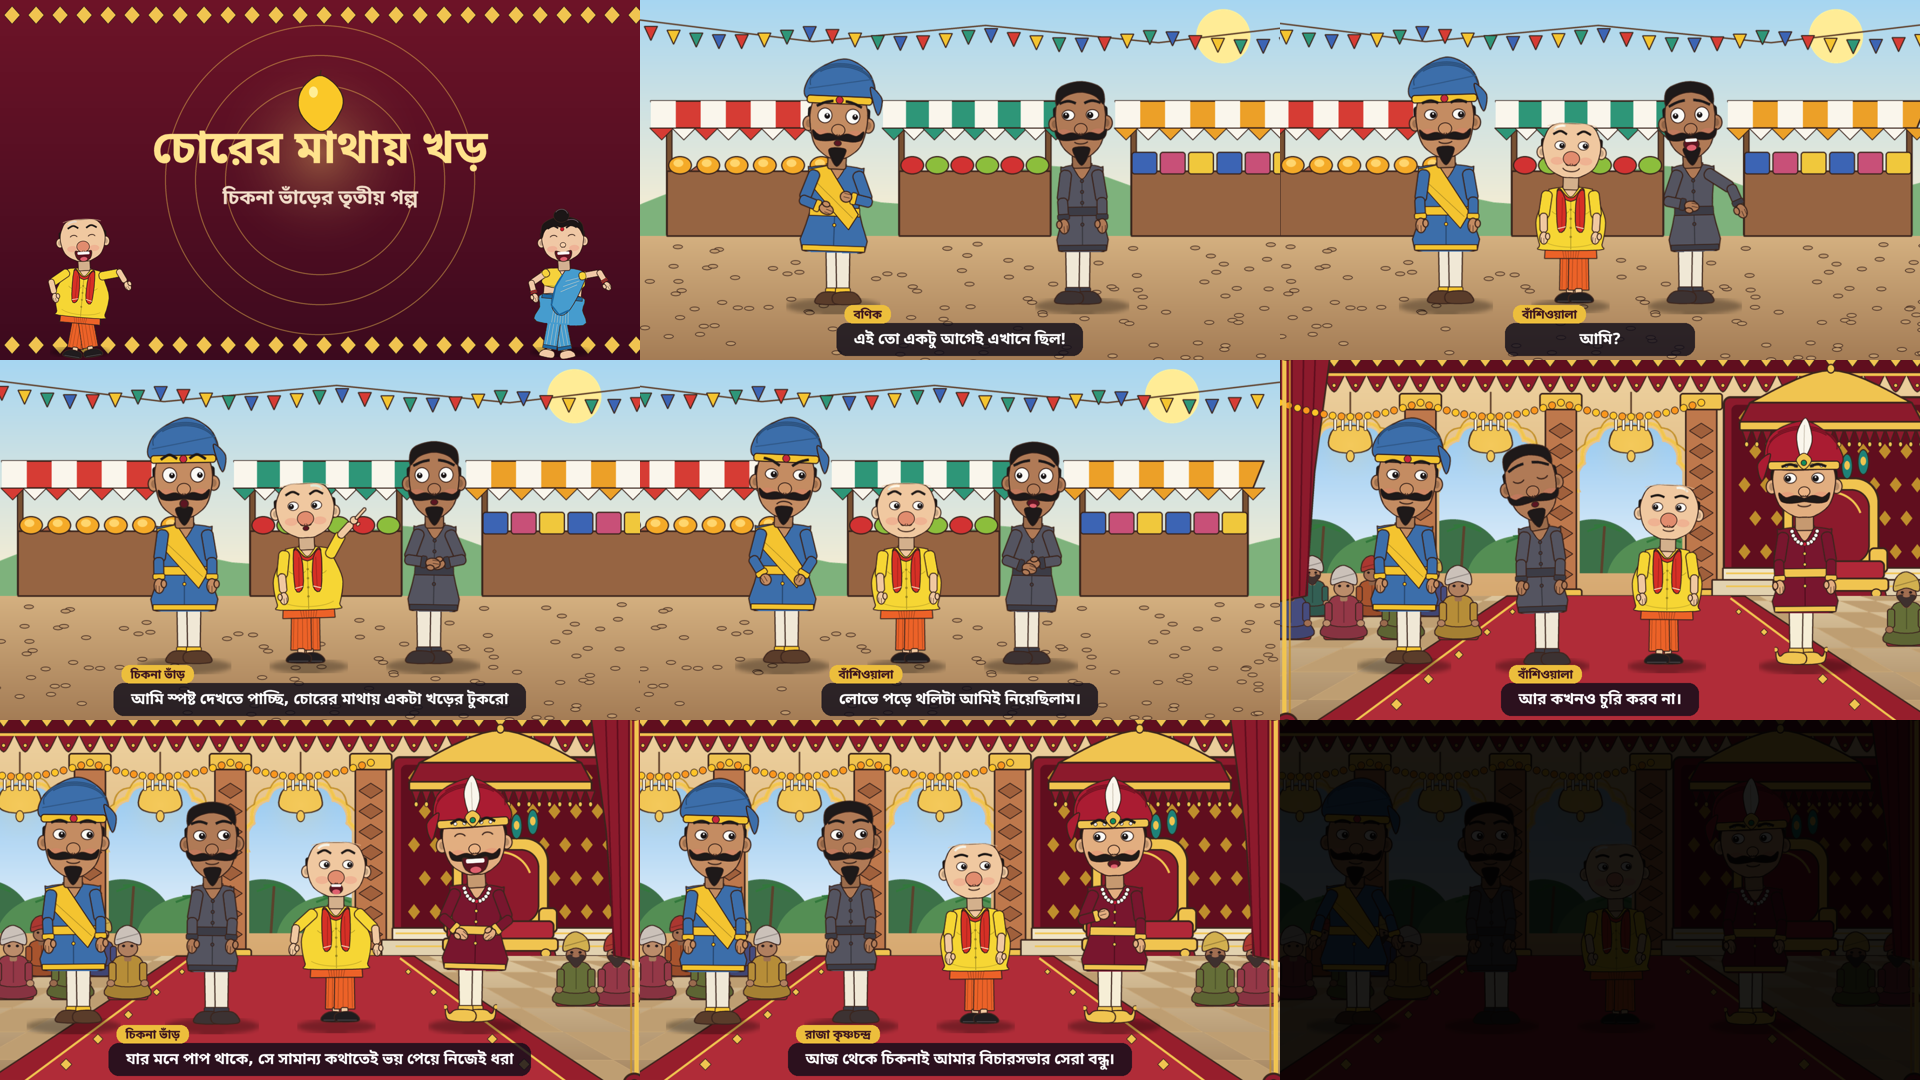

In [8]:
# from engine.render import Studio

# studio = Studio(".", STORY, draft=USE_DRAFT_VOICE_IF_OFFLINE)
# total = studio.tl.total
# print(f"Video length: {total:.0f} seconds ({total / 60:.1f} min)")
# times = [total * f for f in (0.03, 0.12, 0.25, 0.38, 0.5, 0.62, 0.75, 0.88, 0.97)]
# studio.contact_sheet(times, cols=3, scale=0.5)

from engine.render import Studio

studio = Studio(".", STORY, draft=USE_DRAFT_VOICE_IF_OFFLINE)

total = studio.tl.total
print(f"Video length: {total:.0f} seconds ({total / 60:.1f} min)")

times = [
    total * f
    for f in (0.03, 0.12, 0.25, 0.38, 0.5, 0.62, 0.75, 0.88, 0.97)
]

studio.contact_sheet(times, cols=3, scale=0.5)

## 5 · Render the video
About 1–2 minutes for a 2 minute video.  
Optional background music: put a file at `music/music.mp3`. It is mixed in quietly, becomes softer while someone speaks, and fades in and out.

In [9]:
from pathlib import Path
from IPython.display import Video

out = f"output/{Path(STORY).stem}.mp4"
studio.render(out)
Video(out, width=800)

     0.0s / 114.8s  (  0%)  elapsed    0s
    10.0s / 114.8s  (  9%)  elapsed    3s
    20.0s / 114.8s  ( 17%)  elapsed    7s
    30.0s / 114.8s  ( 26%)  elapsed   11s
    40.0s / 114.8s  ( 35%)  elapsed   15s
    50.0s / 114.8s  ( 44%)  elapsed   20s
    60.0s / 114.8s  ( 52%)  elapsed   24s
    70.0s / 114.8s  ( 61%)  elapsed   29s
    80.0s / 114.8s  ( 70%)  elapsed   35s
    90.0s / 114.8s  ( 78%)  elapsed   39s
   100.0s / 114.8s  ( 87%)  elapsed   44s
   110.0s / 114.8s  ( 96%)  elapsed   49s
Saved output/3_straw_on_the_thief.mp4  (114.8 s, 51 s to render)


## Housekeeping (optional)
Shows voice files that the current story no longer uses. Set `delete=True` to remove them.

In [10]:
audio.clean_unused_audio(story, "audio", delete=False)

unused  .gitignore
unused  .gitkeep


[PosixPath('audio/.gitignore'), PosixPath('audio/.gitkeep')]